### Лабораторная работа 3
#### Клименко В.А.

In [40]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)
from sklearn.metrics import confusion_matrix, classification_report

nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

In [41]:
BASE_DIR = "./lab3_data/"
texts = []
labels = []
file_names = []

pos_files = glob.glob(os.path.join(BASE_DIR, "positive", "*.txt"))
neg_files = glob.glob(os.path.join(BASE_DIR, "negative", "*.txt"))

for file_path in pos_files:
    with open(file_path, "r", encoding="utf-8") as f:
        texts.append(f.read())
        labels.append(1)
        file_names.append(os.path.basename(file_path))

for file_path in neg_files:
    with open(file_path, "r", encoding="utf-8") as f:
        texts.append(f.read())
        labels.append(0)
        file_names.append(os.path.basename(file_path))

print(f"✅ Загружено {len(texts)} отзывов")
print(f" Позитивных: {sum(labels)}")
print(f" Негативных: {len(labels) - sum(labels)}")

✅ Загружено 40 отзывов
 Позитивных: 20
 Негативных: 20


In [42]:
import re

stop_words = set(stopwords.words("russian"))


def preprocess(text):
    text = text.lower()
    text = re.sub(r"[^а-яёa-z\s]", " ", text)
    tokens = word_tokenize(text, language="russian")
    tokens = [
        word for word in tokens if word not in stop_words and len(word) >= 3
    ]
    return " ".join(tokens)


texts_processed = [preprocess(t) for t in texts]
print(f"Пример предобработки:")
print(f" БЫЛО: {texts[0][:80]}...")
print(f" СТАЛО: {texts_processed[0][:80]}...")

Пример предобработки:
 БЫЛО: Фильм просто потрясающий! Актерская игра на высшем уровне, 
особенно главную рол...
 СТАЛО: фильм просто потрясающий актерская игра высшем уровне особенно главную роль сыгр...


In [43]:
X_train, X_test, y_train, y_test = train_test_split(
    texts_processed, labels, test_size=0.2, random_state=42, stratify=labels
)

print(f"Размер обучающей выборки: {len(X_train)}")
print(f"Размер тестовой выборки: {len(X_test)}")
print(f"Распределение классов в train: {Counter(y_train)}")
print(f"Распределение классов в test: {Counter(y_test)}")

Размер обучающей выборки: 32
Размер тестовой выборки: 8
Распределение классов в train: Counter({0: 16, 1: 16})
Распределение классов в test: Counter({0: 4, 1: 4})


In [44]:
vectorizer = TfidfVectorizer()
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print(f"Форма X_train_tfidf: {X_train_tfidf.shape}")
print(f"Форма X_test_tfidf: {X_test_tfidf.shape}")
print(f"Размер словаря: {len(vectorizer.get_feature_names_out())}")

Форма X_train_tfidf: (32, 428)
Форма X_test_tfidf: (8, 428)
Размер словаря: 428


In [45]:
model = MultinomialNB()
model.fit(X_train_tfidf, y_train)

print("Модель обучена")

Модель обучена


In [46]:
y_pred = model.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label=1)
recall = recall_score(y_test, y_pred, pos_label=1)
f1 = f1_score(y_test, y_pred, pos_label=1)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")
print("\n" + "=" * 60)
print("Classification Report:")
print("=" * 60)
print(
    classification_report(y_test, y_pred, target_names=["Негатив", "Позитив"])
)

Accuracy: 0.2500
Precision: 0.0000
Recall: 0.0000
F1-score: 0.0000

Classification Report:
              precision    recall  f1-score   support

     Негатив       0.33      0.50      0.40         4
     Позитив       0.00      0.00      0.00         4

    accuracy                           0.25         8
   macro avg       0.17      0.25      0.20         8
weighted avg       0.17      0.25      0.20         8



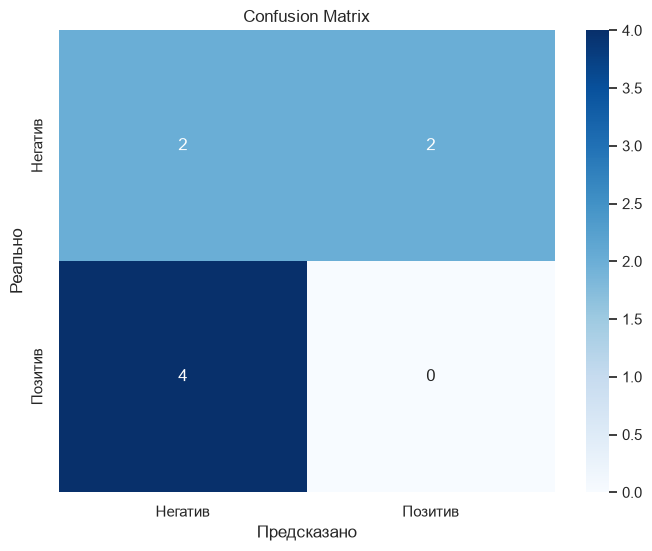


Интерпретация:
 True Negative (правильно предсказан негатив): 2
 False Positive (ошибочно предсказан позитив): 2
 False Negative (ошибочно предсказан негатив): 4
 True Positive (правильно предсказан позитив): 0


In [47]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Негатив", "Позитив"],
    yticklabels=["Негатив", "Позитив"],
)
plt.xlabel("Предсказано")
plt.ylabel("Реально")
plt.title("Confusion Matrix")
plt.show()

print(f"\nИнтерпретация:")
print(f" True Negative (правильно предсказан негатив): {cm[0, 0]}")
print(f" False Positive (ошибочно предсказан позитив): {cm[0, 1]}")
print(f" False Negative (ошибочно предсказан негатив): {cm[1, 0]}")
print(f" True Positive (правильно предсказан позитив): {cm[1, 1]}")

In [48]:
y_test_arr = np.array(y_test)
errors_idx = np.where(y_pred != y_test_arr)[0]

print(f"Количество ошибок: {len(errors_idx)} из {len(y_test)}")
print("\n" + "=" * 60)
print("ОШИБКИ КЛАССИФИКАЦИИ:")
print("=" * 60)
for idx in errors_idx:
    real_label = "Позитив" if y_test[idx] == 1 else "Негатив"
    pred_label = "Позитив" if y_pred[idx] == 1 else "Негатив"
    print(f"\n[{idx}] Реально: {real_label}, Предсказано: {pred_label}")
    print(f"Текст: {texts[idx][:150]}...")
    print("-" * 60)

Количество ошибок: 6 из 8

ОШИБКИ КЛАССИФИКАЦИИ:

[1] Реально: Негатив, Предсказано: Позитив
Текст: Замечательный ресторан! Еда восхитительная, порции большие. 
Обслуживание быстрое и вежливое. Интерьер уютный, атмосфера приятная. 
Цены адекватные дл...
------------------------------------------------------------

[2] Реально: Позитив, Предсказано: Негатив
Текст: Лучший телефон, который у меня был! Камера снимает отлично, 
батарея держит два дня, экран яркий и чёткий. Работает быстро, не тормозит. 
За свои день...
------------------------------------------------------------

[3] Реально: Позитив, Предсказано: Негатив
Текст: Книга читается на одном дыхании! Автор мастерски создаёт атмосферу, 
персонажи живые и запоминающиеся. Сюжет непредсказуемый, концовка удивила. 
Это о...
------------------------------------------------------------

[4] Реально: Негатив, Предсказано: Позитив
Текст: Прекрасный отель! Номер чистый и просторный, вид из окна шикарный. 
Персонал дружелюбный и отзывчивый.

In [49]:
test_files = ["test_positive.txt", "test_negative.txt", "test_neutral.txt"]

for test_file in test_files:
    file_path = os.path.join(BASE_DIR, test_file)
    if os.path.exists(file_path):
        with open(file_path, "r", encoding="utf-8") as f:
            raw_text = f.read()

        processed_text = preprocess(raw_text)
        vector = vectorizer.transform([processed_text])
        pred = model.predict(vector)[0]
        proba = model.predict_proba(vector)[0]

        pred_label = "Позитив" if pred == 1 else "Негатив"
        print(
            f"{test_file:17s} -> {pred_label} "
            f"(P_neg: {proba[0]:.2f}, P_pos: {proba[1]:.2f})"
        )

test_positive.txt -> Позитив (P_neg: 0.46, P_pos: 0.54)
test_negative.txt -> Негатив (P_neg: 0.64, P_pos: 0.36)
test_neutral.txt  -> Негатив (P_neg: 0.55, P_pos: 0.45)


  ngram_range  min_df  accuracy
0      (1, 1)       1     0.250
1      (1, 1)       2     0.500
2      (1, 1)       3     0.625
3      (1, 2)       1     0.125
4      (1, 2)       2     0.500
5      (1, 2)       3     0.750
6      (1, 3)       1     0.250
7      (1, 3)       2     0.625
8      (1, 3)       3     0.750


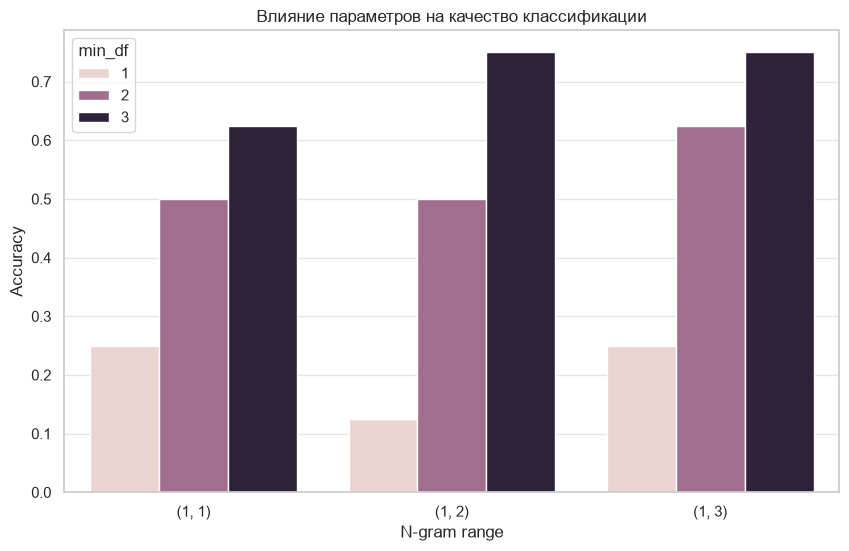

In [50]:
results = []

for ngram in [(1, 1), (1, 2), (1, 3)]:
    for min_df in [1, 2, 3]:
        exp_vec = TfidfVectorizer(ngram_range=ngram, min_df=min_df)
        X_tr_vec = exp_vec.fit_transform(X_train)
        X_te_vec = exp_vec.transform(X_test)

        exp_model = MultinomialNB()
        exp_model.fit(X_tr_vec, y_train)

        preds = exp_model.predict(X_te_vec)
        acc = accuracy_score(y_test, preds)

        results.append(
            {
                "ngram_range": str(ngram),
                "min_df": min_df,
                "accuracy": acc,
            }
        )

df_results = pd.DataFrame(results)
print(df_results)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=df_results,
    x="ngram_range",
    y="accuracy",
    hue="min_df",
)
plt.xlabel("N-gram range")
plt.ylabel("Accuracy")
plt.title("Влияние параметров на качество классификации")
plt.show()

In [51]:
vocab = vectorizer.get_feature_names_out()
log_probs = model.feature_log_prob_

top10_neg_idx = np.argsort(log_probs[0])[-10:][::-1]
top10_neg_words = [vocab[i] for i in top10_neg_idx]

top10_pos_idx = np.argsort(log_probs[1])[-10:][::-1]
top10_pos_words = [vocab[i] for i in top10_pos_idx]

print("Топ-10 слов для НЕГАТИВНЫХ отзывов:")
print(", ".join(top10_neg_words))

print("\nТоп-10 слов для ПОЗИТИВНЫХ отзывов:")
print(", ".join(top10_pos_words))

Топ-10 слов для НЕГАТИВНЫХ отзывов:
деньги, ужасный, время, рекомендую, плохой, впустую, потратил, час, тратьте, завышенные

Топ-10 слов для ПОЗИТИВНЫХ отзывов:
отличный, прекрасный, помогает, очень, спасибо, персонал, увлекательный, работу, интересные, всем


In [52]:
best_exp = df_results.loc[df_results["accuracy"].idxmax()]

summary = {
    "Метрика": [
        "Размер обучающей выборки",
        "Размер тестовой выборки",
        "Размер словаря TF-IDF",
        "Accuracy",
        "Precision (позитив)",
        "Recall (позитив)",
        "F1-score (позитив)",
        "Количество ошибок на тесте",
        "Лучший ngram_range",
        "Лучший min_df",
    ],
    "Значение": [
        len(X_train),
        len(X_test),
        len(vectorizer.get_feature_names_out()),
        round(accuracy, 4),
        round(precision, 4),
        round(recall, 4),
        round(f1, 4),
        len(errors_idx),
        best_exp["ngram_range"],
        best_exp["min_df"],
    ],
}
pd.DataFrame(summary)

,Метрика,Значение
0,Размер обучающей выборки,32
1,Размер тестовой выборки,8
2,Размер словаря TF-IDF,428
3,Accuracy,0.25
4,Precision (позитив),0.0
5,Recall (позитив),0.0
6,F1-score (позитив),0.0
7,Количество ошибок на тесте,6
8,Лучший ngram_range,"(1, 2)"
9,Лучший min_df,3
